## IMPORT GRAPH

Edges after filters: 144
KRAS subgraph: 61 genes, 129 edges


C:\Users\ironl\AppData\Local\Temp\ipykernel_2284\2604997054.py:150: UserWarning: 

The connectionstyle keyword argument is not applicable when drawing edges
with LineCollection.

To make this warning go away, either specify `arrows=True` to
force FancyArrowPatches or use the default values.
Note that using FancyArrowPatches may be slow for large graphs.

  nx.draw_networkx_edges(


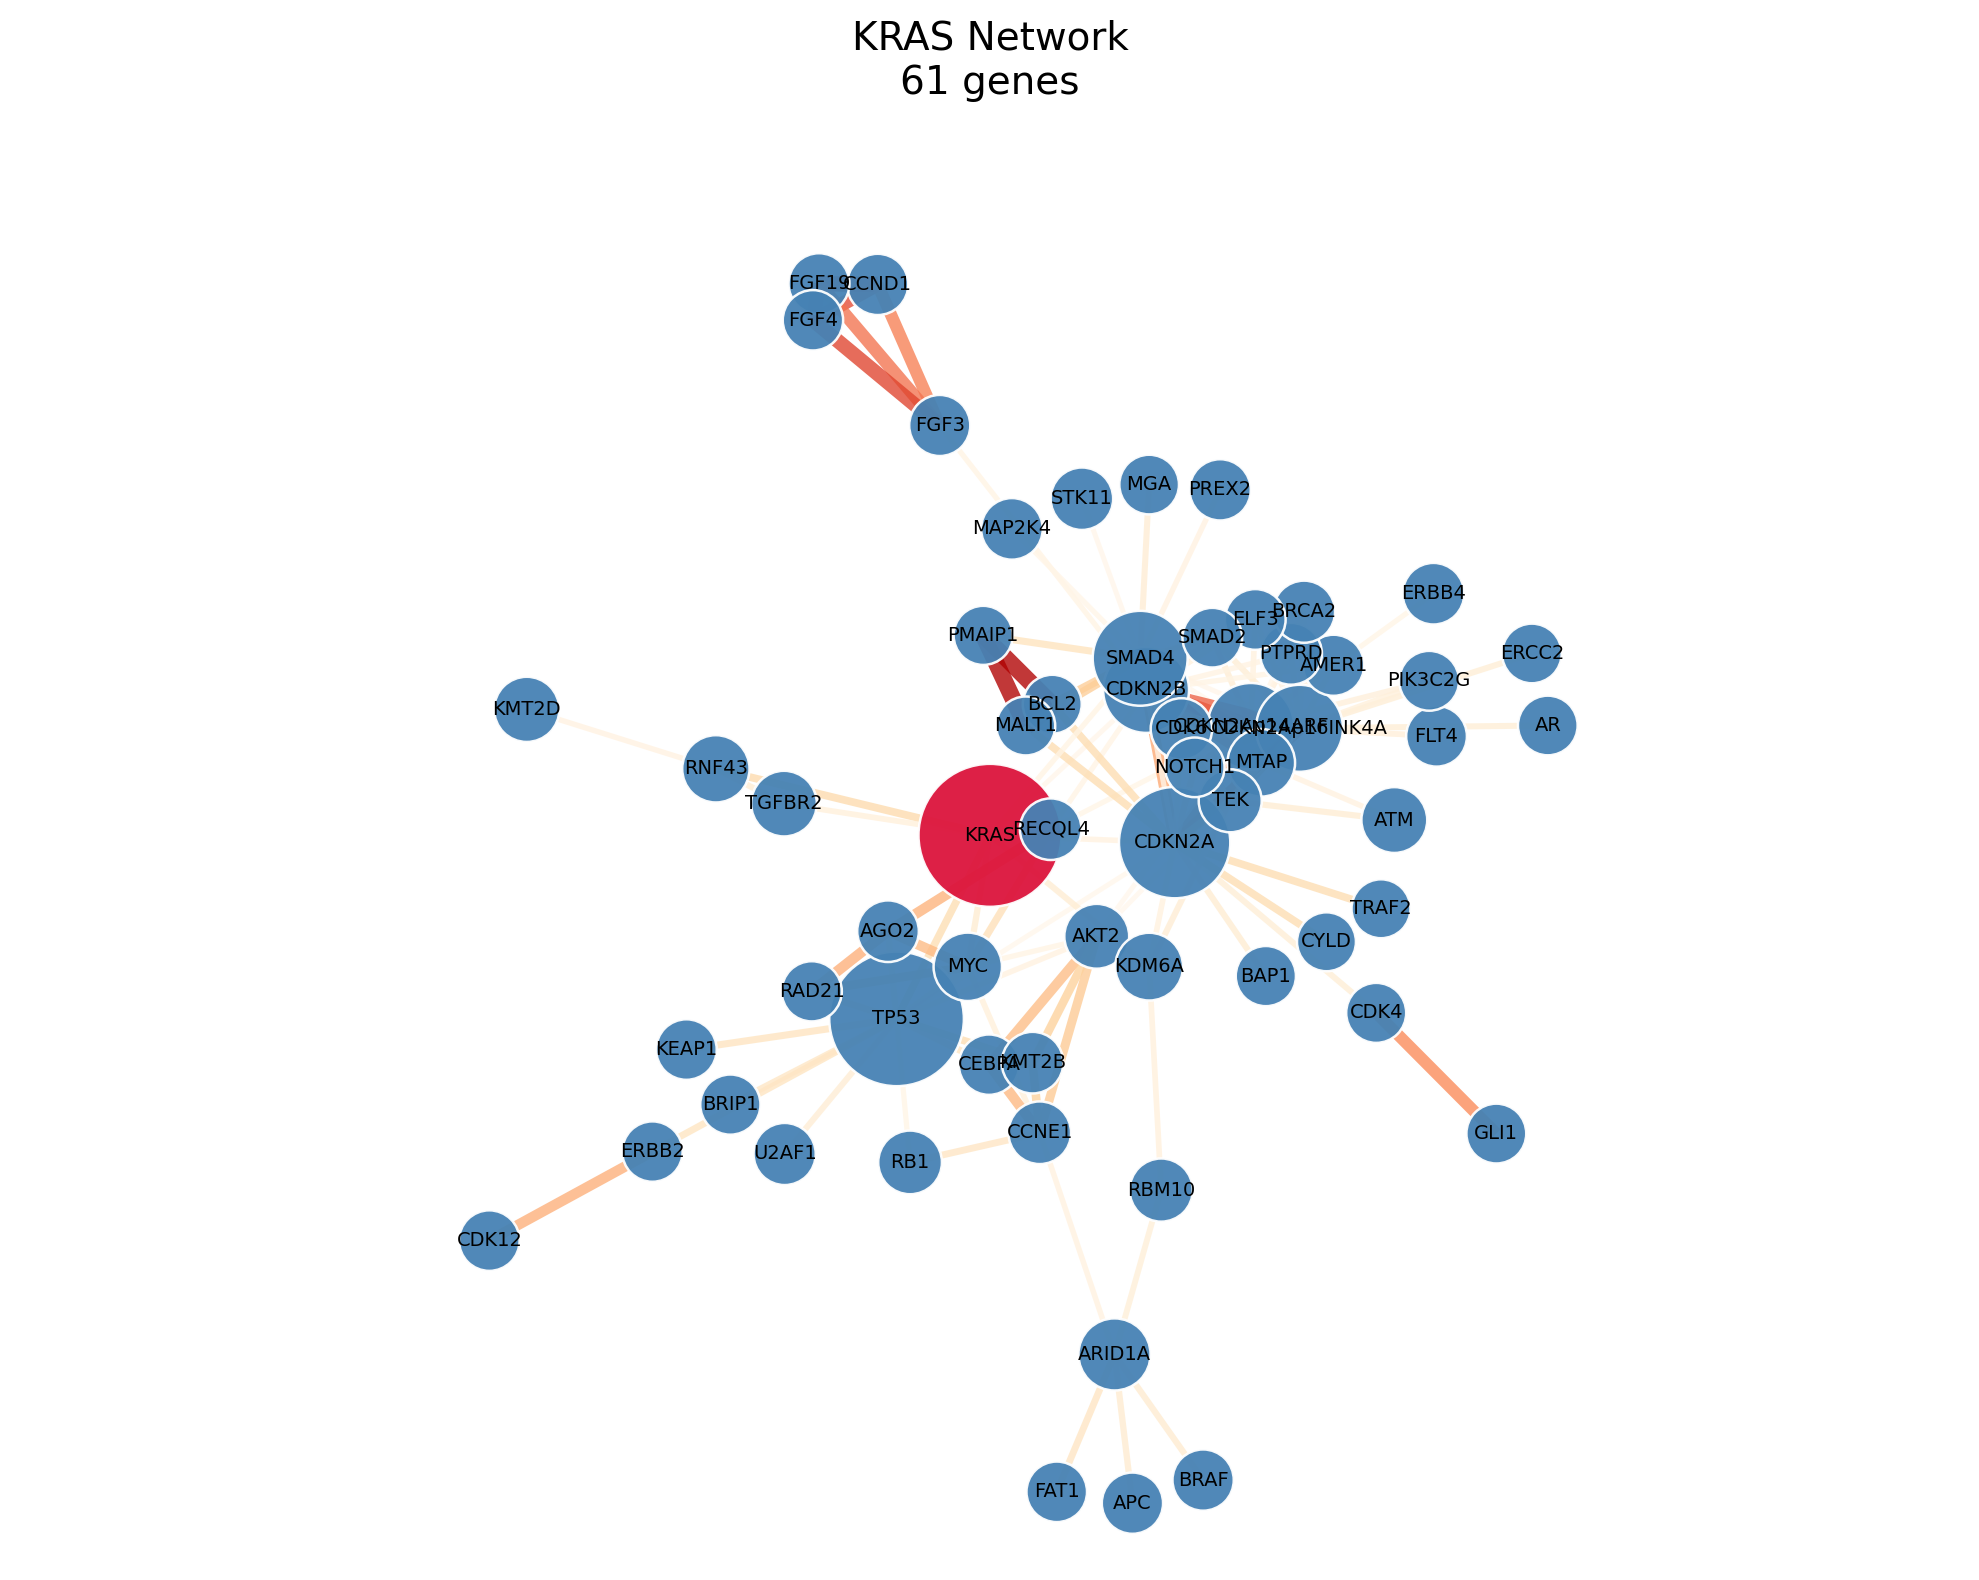

In [1]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

# ---------------------------
# KRAS-focused network settings (same logic as cell 5 in log2test-v2)
# ---------------------------
min_log2_or = 1
max_p_value = 0.05
min_shared = 5
max_hops_from_kras = None  # None = keep full KRAS connected component

# Build graph from merged results with strict statistical filters.
file_path_merged = Path("data_pancreas") / "merged_mutations_cna_sv.csv"
df_merge = pd.read_csv(file_path_merged, low_memory=False)

tmp_m = (
    df_merge[["Patient_ID", "Hugo_Symbol"]]
    .dropna()
    .drop_duplicates()
)

# Patient x Gene binary matrix
patient_gene_m = pd.crosstab(tmp_m["Patient_ID"], tmp_m["Hugo_Symbol"]).astype(bool).astype(int)
N_m = patient_gene_m.shape[0]
gene_counts_m = patient_gene_m.sum(axis=0)

# Co-occurrence matrix
co_m = patient_gene_m.T @ patient_gene_m
co_m_np = co_m.to_numpy(copy=True)
np.fill_diagonal(co_m_np, 0)
co_m = pd.DataFrame(co_m_np, index=co_m.index, columns=co_m.columns)

edges_m = (
    co_m.where(np.triu(np.ones(co_m.shape), k=1).astype(bool))
    .stack()
    .rename("a_both")
    .rename_axis(index=["Gene1", "Gene2"])
    .reset_index()
)
edges_m = edges_m.dropna(subset=["a_both"]).copy()
edges_m["a_both"] = edges_m["a_both"].astype(int)

rows_m = []
from scipy.stats import fisher_exact
for r in edges_m.itertuples(index=False):
    g1, g2, a = r.Gene1, r.Gene2, int(r.a_both)
    b = int(gene_counts_m[g1] - a)
    c = int(gene_counts_m[g2] - a)
    d = int(N_m - a - b - c)

    odds_ratio, p_value = fisher_exact([[a, b], [c, d]], alternative="greater")
    log2_or = np.log2(((a + 0.5) * (d + 0.5)) / ((b + 0.5) * (c + 0.5)))
    rows_m.append([g1, g2, a, b, c, d, odds_ratio, log2_or, p_value])

results_m = pd.DataFrame(
    rows_m,
    columns=[
        "Gene1", "Gene2", "a_both", "b_g1_only", "c_g2_only", "d_neither",
        "odds_ratio", "log2_OR", "p_value"
    ]
)

edges_plot = (
    results_m[
        (results_m["log2_OR"] > min_log2_or) &
        (results_m["p_value"] < max_p_value) &
        (results_m["a_both"] >= min_shared)
        ]
    .sort_values(["p_value", "log2_OR"], ascending=[True, False])
    .copy()
)

print(f"Edges after filters: {len(edges_plot)}")

G_plot = nx.Graph()
for _, row in edges_plot.iterrows():
    G_plot.add_edge(
        row["Gene1"],
        row["Gene2"],
        log2_or=float(row["log2_OR"]),
        p_value=float(row["p_value"]),
        shared=int(row["a_both"]),
    )

if G_plot.number_of_nodes() == 0 or G_plot.number_of_edges() == 0:
    print("No edges to display with current thresholds.")
else:
    kras_nodes = [n for n in G_plot.nodes() if str(n).upper() == "KRAS"]

    if not kras_nodes:
        print("KRAS is not present with these thresholds. Relax filters.")
    else:
        kras_node = kras_nodes[0]
        distances = nx.single_source_shortest_path_length(G_plot, kras_node)

        if max_hops_from_kras is None:
            keep_nodes = set(distances.keys())
        else:
            keep_nodes = {n for n, d in distances.items() if d <= max_hops_from_kras}

        G_kras = G_plot.subgraph(keep_nodes).copy()

        print(f"KRAS subgraph: {G_kras.number_of_nodes()} genes, {G_kras.number_of_edges()} edges")

        if G_kras.number_of_edges() == 0:
            print("KRAS has no connected edges with current thresholds/hops.")
        else:
            plt.figure(figsize=(10, 8), dpi=200)

            local_dist = nx.single_source_shortest_path_length(G_kras, kras_node)
            max_d = max(local_dist.values())
            shells = [[kras_node]] + [
                [n for n in G_kras.nodes() if local_dist[n] == d]
                for d in range(1, max_d + 1)
            ]
            pos0 = nx.shell_layout(G_kras, nlist=shells)
            pos0[kras_node] = np.array([0.0, 0.0])

            pos = nx.spring_layout(
                G_kras,
                seed=42,
                k=0.9,
                pos=pos0,
                fixed=[kras_node],
                center=(0, 0),
                iterations=200,
            )

            gene_support = gene_counts_m.to_dict()
            support_vals = [float(gene_support.get(n, 1)) for n in G_kras.nodes()]
            s_min = min(support_vals) if support_vals else 1.0
            s_max = max(support_vals) if support_vals else 1.0
            if s_max == s_min:
                node_sizes = [1000 for _ in G_kras.nodes()]
            else:
                node_sizes = [
                    450 + 2200 * ((float(gene_support.get(n, s_min)) - s_min) / (s_max - s_min))
                    for n in G_kras.nodes()
                ]

            node_colors = ["crimson" if str(n).upper() == "KRAS" else "steelblue" for n in G_kras.nodes()]

            edge_vals = [G_kras[u][v].get("log2_or", 1.0) for u, v in G_kras.edges()]
            max_edge = max(edge_vals) if edge_vals else 1.0
            edge_widths = [1.4 + 5.2 * (w / max_edge) for w in edge_vals]

            nx.draw_networkx_edges(
                G_kras,
                pos,
                width=edge_widths,
                alpha=0.78,
                edge_color=edge_vals,
                edge_cmap=plt.cm.OrRd,
                edge_vmin=min(edge_vals) if edge_vals else 0.0,
                edge_vmax=max(edge_vals) if edge_vals else 1.0,
                connectionstyle="arc3,rad=0.06",
            )

            nx.draw_networkx_nodes(
                G_kras,
                pos,
                node_size=node_sizes,
                node_color=node_colors,
                alpha=0.95,
                linewidths=0.9,
                edgecolors="white",
            )

            labels_all = {n: n for n in G_kras.nodes()}
            nx.draw_networkx_labels(G_kras, pos, labels=labels_all, font_size=7)

            xy = np.array(list(pos.values()))
            r = float(np.abs(xy).max()) if xy.size else 1.0
            lim = r + (0.08 * r + 0.05)
            plt.xlim(-lim, lim)
            plt.ylim(-lim, lim)

            plt.title(
                f"KRAS Network\n"
                f"{G_kras.number_of_nodes()} genes",
                fontsize=14,
            )
            plt.axis("off")
            plt.tight_layout()
            plt.show()

***
## HUB MUTATION centrality metrics

In [2]:
import pandas as pd
import networkx as nx
import numpy as np

# =========================
# 1. Choose graph to analyze
# =========================

candidate_graphs = ["G_kras", "G_comm", "G_hub", "G"]

available_graphs = []

for name in candidate_graphs:
    if name in globals() and isinstance(globals()[name], nx.Graph) and globals()[name].number_of_nodes() > 0:
        G_tmp = globals()[name]
        available_graphs.append({
            "Graph": name,
            "Nodes": G_tmp.number_of_nodes(),
            "Edges": G_tmp.number_of_edges(),
            "Density": nx.density(G_tmp),
            "Max_possible_edges": G_tmp.number_of_nodes() * (G_tmp.number_of_nodes() - 1) // 2
        })

if not available_graphs:
    raise ValueError("Nessuna rete disponibile. Esegui prima le celle di costruzione della rete.")

density_df = pd.DataFrame(available_graphs)

print("Available graphs:")
display(density_df)

# Priority: KRAS-focused network, then community network, then hub graph, then generic G
selected_graph_name = density_df.iloc[0]["Graph"]
G_selected = globals()[selected_graph_name]

density = nx.density(G_selected)

print(f"\nSelected graph: {selected_graph_name}")
print(f"Nodes: {G_selected.number_of_nodes()} | Edges: {G_selected.number_of_edges()}")
print(f"Density: {density:.4f}")

if density < 0.01:
    density_interpretation = "Very sparse"
elif density < 0.05:
    density_interpretation = "Sparse"
elif density < 0.1:
    density_interpretation = "Moderately sparse"
elif density < 0.3:
    density_interpretation = "Moderate"
else:
    density_interpretation = "Dense"

print(f"Interpretation: {density_interpretation}")

Available graphs:


,Graph,Nodes,Edges,Density,Max_possible_edges
0,G_kras,61,129,0.070492,1830



Selected graph: G_kras
Nodes: 61 | Edges: 129
Density: 0.0705
Interpretation: Moderately sparse


In [3]:
# =========================
# 2. Hub metrics calculation
# =========================

G_hub = G_selected.copy()
graph_name = selected_graph_name

# Decide whether to include eigenvector centrality
# If the graph is too sparse or disconnected, eigenvector can be unstable/not meaningful.
use_eigenvector = True

if nx.density(G_hub) < 0.1:
    use_eigenvector = False
    print("Eigenvector centrality will NOT be included because the graph is very sparse.")
elif not nx.is_connected(G_hub):
    use_eigenvector = False
    print("Eigenvector centrality will NOT be included because the graph is disconnected.")
else:
    print("Eigenvector centrality will be included.")

# Basic centrality metrics
degree = dict(G_hub.degree())

strength = {
    n: sum(G_hub[n][nbr].get("log2_or", 1.0) for nbr in G_hub.neighbors(n))
    for n in G_hub.nodes()
}

betweenness = nx.betweenness_centrality(G_hub, normalized=True)
closeness = nx.closeness_centrality(G_hub)

# Eigenvector centrality only if meaningful
if use_eigenvector:
    try:
        eigenvector = nx.eigenvector_centrality_numpy(G_hub)
    except Exception:
        eigenvector = {n: np.nan for n in G_hub.nodes()}
        use_eigenvector = False
        print("Eigenvector centrality failed and will NOT be included.")
else:
    eigenvector = {n: np.nan for n in G_hub.nodes()}

# Create hub table
hub_table = pd.DataFrame({
    "Gene": list(G_hub.nodes()),
    "Degree": [degree[n] for n in G_hub.nodes()],
    "Node Strength": [strength[n] for n in G_hub.nodes()],
    "Betweenness": [betweenness[n] for n in G_hub.nodes()],
    "Closeness": [closeness[n] for n in G_hub.nodes()],
    "Eigenvector": [eigenvector[n] for n in G_hub.nodes()],
})

# Additional useful metrics
n_nodes = G_hub.number_of_nodes()
denom = (n_nodes - 1) if n_nodes > 1 else 1

hub_table["Degree_norm"] = hub_table["Degree"] / denom

hub_table["Mean_log2_or_per_edge"] = (
        hub_table["Node Strength"] / hub_table["Degree"].replace(0, pd.NA)
)

# =========================
# 3. Composite HubScore
# =========================

if use_eigenvector:
    hub_table["HubScore"] = (
            hub_table["Degree"].rank(pct=True) * 0.20
            + hub_table["Node Strength"].rank(pct=True) * 0.20
            + hub_table["Betweenness"].rank(pct=True) * 0.20
            + hub_table["Closeness"].rank(pct=True) * 0.20
            + hub_table["Eigenvector"].fillna(0).rank(pct=True) * 0.20
    )

    score_description = (
        "HubScore = 20% Degree + 20% Node Strength + 20% Betweenness "
        "+ 20% Closeness + 20% Eigenvector"
    )

else:
    hub_table["HubScore"] = (
            hub_table["Degree"].rank(pct=True) * 0.25
            + hub_table["Node Strength"].rank(pct=True) * 0.25
            + hub_table["Betweenness"].rank(pct=True) * 0.25
            + hub_table["Closeness"].rank(pct=True) * 0.25
    )

    score_description = (
        "HubScore = 25% Degree + 25% Node Strength + 25% Betweenness "
        "+ 25% Closeness"
    )

hub_table = hub_table.sort_values("HubScore", ascending=False).reset_index(drop=True)

# =========================
# 4. Display results
# =========================

top_n = 20

print(f"Graph analyzed: {graph_name}")
print(f"Nodes: {G_hub.number_of_nodes()} | Edges: {G_hub.number_of_edges()}")
print(f"Density: {nx.density(G_hub):.4f}")
print(score_description)
print(f"\nTop {top_n} hub genes:")

display_cols = [
    "Gene",
    "Degree",
    "Degree_norm",
    "Node Strength",
    "Mean_log2_or_per_edge",
    "Betweenness",
    "Closeness",
]

if use_eigenvector:
    display_cols.append("Eigenvector")

display_cols.append("HubScore")

display(hub_table[display_cols].head(top_n))

Eigenvector centrality will NOT be included because the graph is very sparse.
Graph analyzed: G_kras
Nodes: 61 | Edges: 129
Density: 0.0705
HubScore = 25% Degree + 25% Node Strength + 25% Betweenness + 25% Closeness

Top 20 hub genes:


,Gene,Degree,Degree_norm,Node Strength,Mean_log2_or_per_edge,Betweenness,Closeness,HubScore
0,CDKN2A,17,0.283333,60.496365,3.558610,0.312872,0.517241,0.981557
1,CDKN2Ap16INK4A,18,0.300000,65.524587,3.640255,0.156224,0.472441,0.969262
2,CDKN2Ap14ARF,18,0.300000,63.408059,3.522670,0.140123,0.476190,0.965164
3,CDKN2B,15,0.250000,54.539375,3.635958,0.179583,0.461538,0.944672
4,SMAD4,17,0.283333,33.409786,1.965282,0.190602,0.454545,0.932377
5,TP53,13,0.216667,32.438734,2.495287,0.244087,0.428571,0.915984
6,KRAS,8,0.133333,18.070273,2.258784,0.159998,0.461538,0.856557
7,MTAP,7,0.116667,37.977262,5.425323,0.014511,0.410959,0.831967
8,TEK,8,0.133333,26.129617,3.266202,0.034014,0.428571,0.831967
9,AKT2,7,0.116667,20.653853,2.950550,0.111235,0.416667,0.823770


### TOP 10 % MUTATIONAL HUB IN PANCREAS ALL GRAPH

In [4]:
score_col = "HubScore_1over5" if "HubScore_1over5" in hub_table.columns else ("HubScore_equal" if "HubScore_equal" in hub_table.columns else "HubScore")
if score_col not in hub_table.columns:
    raise ValueError("Nessuna colonna HubScore trovata. Esegui prima la cella hub metrics / ranking.")
table = hub_table[["Gene", score_col]].copy().rename(columns={score_col: "HubScore"})

threshold = table["HubScore"].quantile(0.90)
top_genes = (
    table.loc[table["HubScore"] >= threshold]
    .sort_values("HubScore", ascending=False)["Gene"]
    .astype(str)
    .tolist()
)

print(" ".join(top_genes))

CDKN2A CDKN2Ap16INK4A CDKN2Ap14ARF CDKN2B SMAD4 TP53 KRAS


In [5]:
# ============================================================
# POSIZIONE DI KRAS NEL RANKING HUBSCORE
# PANCREAS / KRAS-FOCUSED GRAPH
# ============================================================

if "hub_table" not in globals() or not isinstance(hub_table, pd.DataFrame) or hub_table.empty:
    raise ValueError("hub_table non disponibile. Esegui prima la cella degli hub globali.")

score_col = "HubScore"

if score_col not in hub_table.columns:
    raise ValueError("Colonna HubScore non trovata in hub_table.")

ranking = hub_table[["Gene", score_col]].copy()
ranking = ranking.rename(columns={score_col: "HubScore"})

ranking["Gene"] = ranking["Gene"].astype(str)
ranking["HubScore"] = pd.to_numeric(ranking["HubScore"], errors="coerce")

ranking = (
    ranking
    .dropna(subset=["Gene", "HubScore"])
    .sort_values("HubScore", ascending=False)
    .reset_index(drop=True)
)

ranking["Rank"] = ranking.index + 1

kras_row = ranking[
    ranking["Gene"].str.upper() == "KRAS"
    ]

print("\n" + "=" * 80)
print("KRAS position in global pancreas/KRAS-focused hub ranking")

if kras_row.empty:
    print("KRAS non presente nella hub_table.")
else:
    kras_rank = int(kras_row.iloc[0]["Rank"])
    kras_score = float(kras_row.iloc[0]["HubScore"])

    print(f"KRAS è in posizione: {kras_rank} su {len(ranking)} geni")
    print(f"HubScore di KRAS: {kras_score:.4f}")

display(ranking.head(20))


KRAS position in global pancreas/KRAS-focused hub ranking
KRAS è in posizione: 7 su 61 geni
HubScore di KRAS: 0.8566


,Gene,HubScore,Rank
0,CDKN2A,0.981557,1
1,CDKN2Ap16INK4A,0.969262,2
2,CDKN2Ap14ARF,0.965164,3
3,CDKN2B,0.944672,4
4,SMAD4,0.932377,5
5,TP53,0.915984,6
6,KRAS,0.856557,7
7,MTAP,0.831967,8
8,TEK,0.831967,9
9,AKT2,0.823770,10


In [6]:
# ============================================================
# RUOLO DI KRAS NEL NETWORK
# PANCREAS / KRAS-FOCUSED GRAPH
# ============================================================

if "hub_table" not in globals() or not isinstance(hub_table, pd.DataFrame) or hub_table.empty:
    raise ValueError("hub_table non disponibile. Esegui prima la cella degli hub globali.")

if "G_kras" not in globals() or not isinstance(G_kras, nx.Graph) or G_kras.number_of_nodes() == 0:
    raise ValueError("G_kras non disponibile. Esegui prima la cella di costruzione del grafo.")

role_df = hub_table.copy()
role_df["Gene"] = role_df["Gene"].astype(str)

score_col = "HubScore"

if score_col not in role_df.columns:
    raise ValueError("Colonna HubScore non trovata in hub_table.")

role_df["HubScore_used"] = pd.to_numeric(role_df[score_col], errors="coerce")

for col in ["Degree", "Node Strength", "Betweenness", "Closeness", "Eigenvector"]:
    if col in role_df.columns:
        role_df[col] = pd.to_numeric(role_df[col], errors="coerce")

# Soglie percentili
degree_q90 = role_df["Degree"].quantile(0.90)
degree_q25 = role_df["Degree"].quantile(0.25)

strength_q90 = role_df["Node Strength"].quantile(0.90)
betweenness_q90 = role_df["Betweenness"].quantile(0.90)
betweenness_q25 = role_df["Betweenness"].quantile(0.25)

hubscore_q90 = role_df["HubScore_used"].quantile(0.90)
closeness_q90 = role_df["Closeness"].quantile(0.90)

# Articulation points e clustering coefficient
try:
    articulation_points = set(nx.articulation_points(G_kras))
except Exception:
    articulation_points = set()

try:
    clustering_map = nx.clustering(G_kras)
except Exception:
    clustering_map = {}

role_df["Is_articulation_point"] = role_df["Gene"].isin(
    [str(g) for g in articulation_points]
)

role_df["Clustering_coefficient"] = role_df["Gene"].map(
    lambda g: clustering_map.get(g, np.nan)
)

# Flag topologici
role_df["Is_high_degree"] = role_df["Degree"] >= degree_q90
role_df["Is_high_strength"] = role_df["Node Strength"] >= strength_q90
role_df["Is_high_betweenness"] = role_df["Betweenness"] >= betweenness_q90
role_df["Is_high_closeness"] = role_df["Closeness"] >= closeness_q90
role_df["Is_high_hubscore"] = role_df["HubScore_used"] >= hubscore_q90

role_df["Is_low_degree"] = role_df["Degree"] <= degree_q25
role_df["Is_low_betweenness"] = role_df["Betweenness"] <= betweenness_q25

role_df["Is_hub_like"] = (
        role_df["Is_high_hubscore"]
        | role_df["Is_high_degree"]
        | role_df["Is_high_strength"]
)

role_df["Is_bridge_like"] = (
        role_df["Is_high_betweenness"]
        | role_df["Is_articulation_point"]
)

def assign_role(row):
    if row["Is_hub_like"] and row["Is_bridge_like"]:
        return "Hub-Bridge"

    if row["Is_hub_like"]:
        return "Hub"

    if row["Is_bridge_like"]:
        return "Bridge/Connector"

    if row["Is_low_degree"] and row["Is_low_betweenness"]:
        return "Peripheral"

    if row["Is_high_closeness"]:
        return "Central/Close"

    return "Intermediate"

role_df["Network_role"] = role_df.apply(assign_role, axis=1)

def role_reason(row):
    reasons = []

    if row["Is_high_hubscore"]:
        reasons.append("high HubScore")

    if row["Is_high_degree"]:
        reasons.append("high Degree")

    if row["Is_high_strength"]:
        reasons.append("high Node Strength")

    if row["Is_high_betweenness"]:
        reasons.append("high Betweenness")

    if row["Is_articulation_point"]:
        reasons.append("articulation point")

    if row["Is_high_closeness"]:
        reasons.append("high Closeness")

    if row["Is_low_degree"] and row["Is_low_betweenness"]:
        reasons.append("low Degree and low Betweenness")

    if len(reasons) == 0:
        reasons.append("no extreme centrality metric")

    return "; ".join(reasons)

role_df["Role_reason"] = role_df.apply(role_reason, axis=1)

role_df["Rank_by_HubScore"] = (
    role_df["HubScore_used"]
    .rank(method="first", ascending=False)
    .astype(int)
)

kras_role = role_df[
    role_df["Gene"].str.upper() == "KRAS"
    ].copy()

cols_to_show = [
    "Gene",
    "Network_role",
    "Role_reason",
    "Rank_by_HubScore",
    "HubScore_used",
    "Degree",
    "Node Strength",
    "Betweenness",
    "Closeness",
    "Is_articulation_point",
    "Clustering_coefficient"
]

cols_to_show = [col for col in cols_to_show if col in kras_role.columns]

print("\n" + "=" * 80)
print("KRAS role in pancreas/KRAS-focused network")

display(kras_role[cols_to_show])


KRAS role in pancreas/KRAS-focused network


,Gene,Network_role,Role_reason,Rank_by_HubScore,HubScore_used,Degree,Node Strength,Betweenness,Closeness,Is_articulation_point,Clustering_coefficient
6,KRAS,Hub-Bridge,high HubScore; high Degree; high Betweenness; ...,7,0.856557,8,18.070273,0.159998,0.461538,True,0.25


***
## CLUSTERING

### 1. Leiden e Louvain Stability con ARI

Graph analyzed: G_kras
Nodes: 61 | Edges: 129

=== Louvain Stability (ARI) ===
Mean ARI: 0.9580
Std ARI: 0.0463
Min ARI: 0.8029
Max ARI: 1.0000

=== Leiden Stability (ARI) ===
Mean ARI: 0.9302
Std ARI: 0.0723
Min ARI: 0.8029
Max ARI: 1.0000

=== Louvain Modularity ===
Mean modularity: 0.6384
Std modularity: 0.0004
Min modularity: 0.6360
Max modularity: 0.6386

=== Leiden Modularity ===
Mean modularity: 0.6383
Std modularity: 0.0008
Min modularity: 0.6360
Max modularity: 0.6386

=== Number of clusters frequency ===


,Algorithm,Num_clusters,Frequency,Percentage
0,Louvain,6,10,10.0
1,Louvain,7,90,90.0
2,Leiden,7,100,100.0



Most frequent Louvain partition: 7 clusters (90/100 runs, 90.0%)
Most frequent Leiden partition: 7 clusters (100/100 runs, 100.0%)


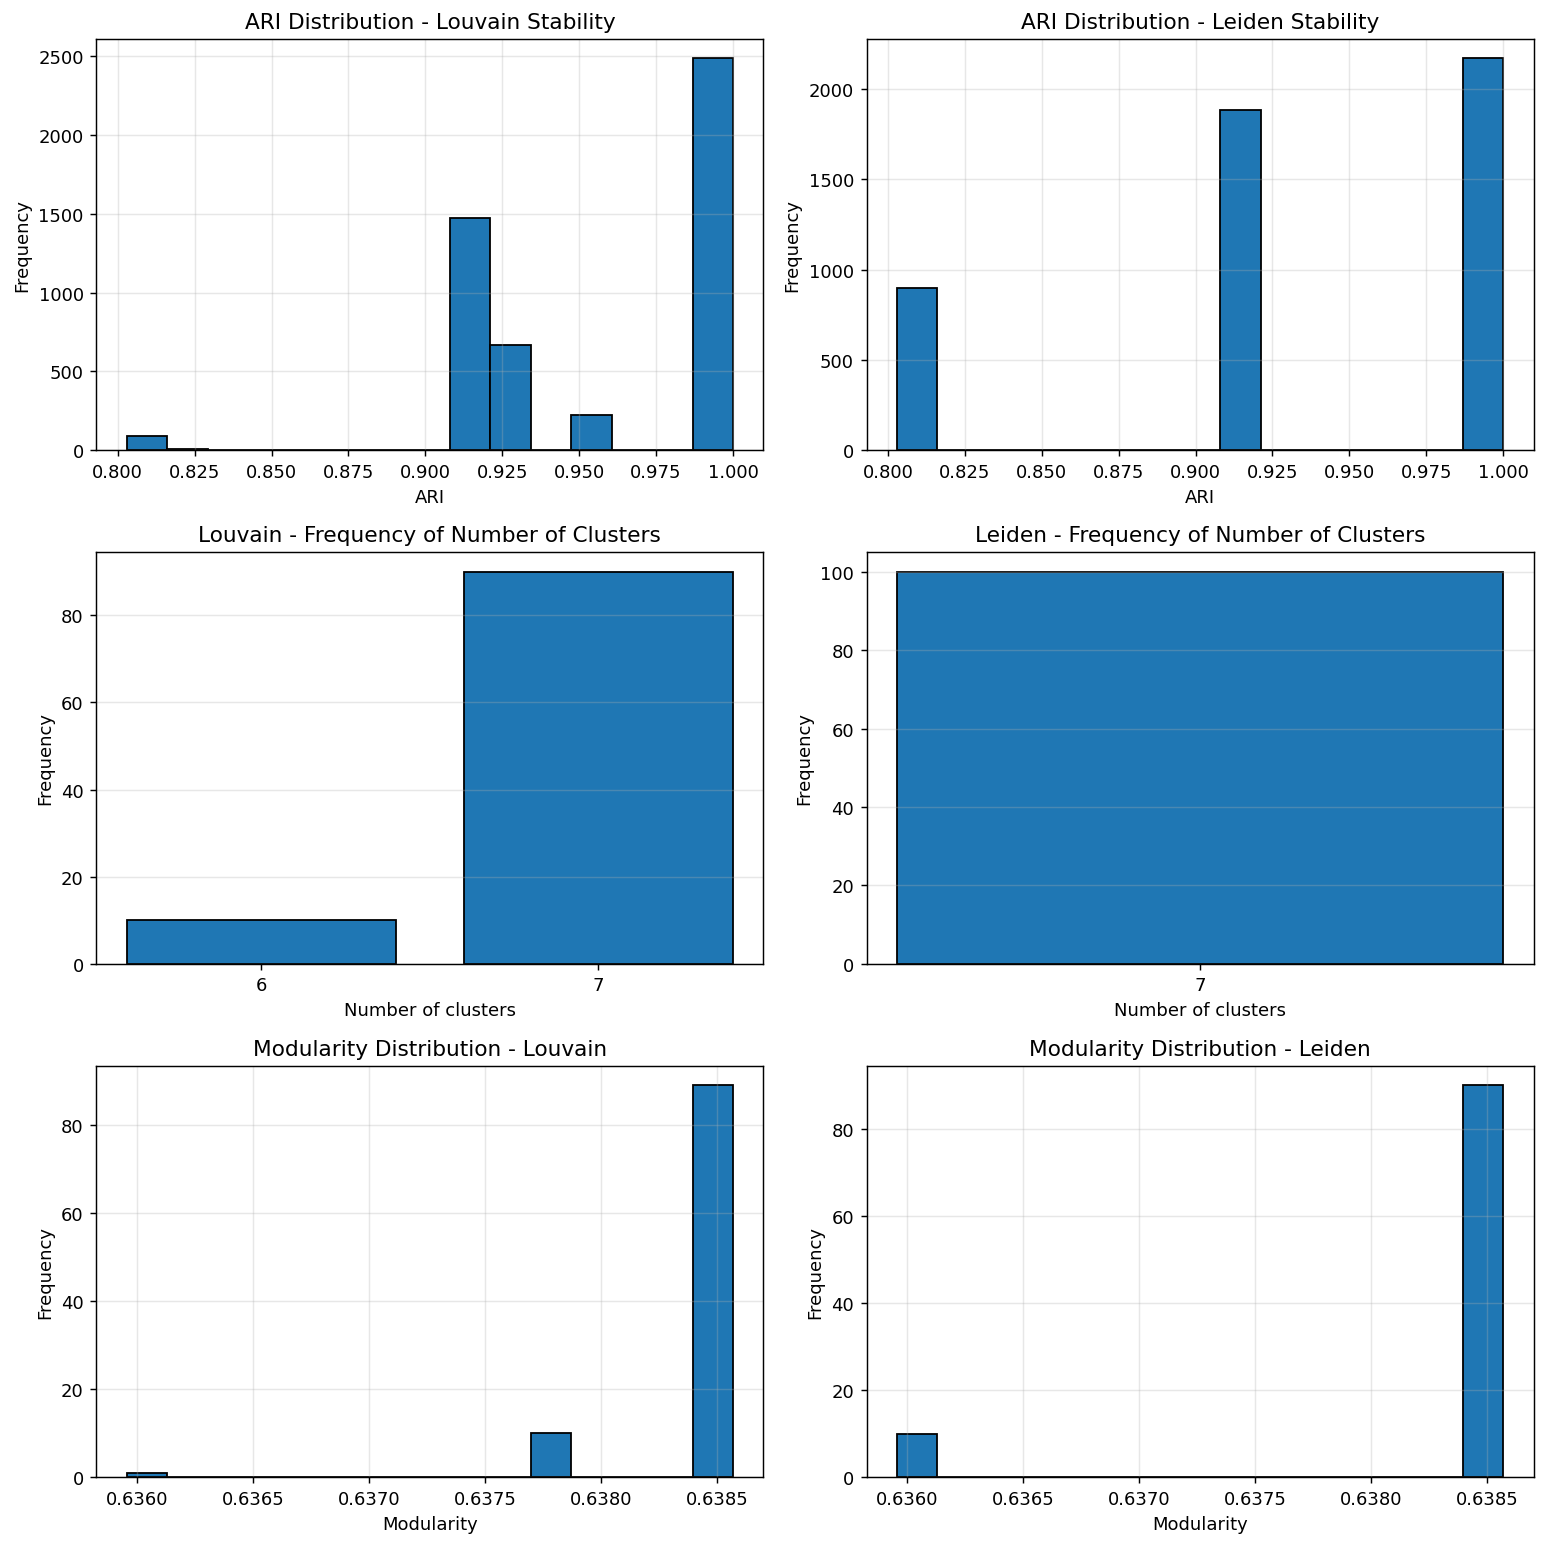

In [7]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score
from collections import Counter

try:
    import igraph as ig
    import leidenalg
except ImportError as e:
    raise ImportError(
        "Per usare Leiden devi installare 'igraph' e 'leidenalg'. "
        "Esempio: pip install python-igraph leidenalg"
    ) from e

# -----------------------------
# Graph selection
# -----------------------------
G_test = G_kras
graph_name = "G_kras"

print(f"Graph analyzed: {graph_name}")
print(f"Nodes: {G_test.number_of_nodes()} | Edges: {G_test.number_of_edges()}")

# -----------------------------
# Parameters
# -----------------------------
n_runs = 100
seeds = list(range(n_runs))
node_list = list(G_test.nodes())

# ============================================================
# LOUVAIN MULTIPLE RUNS
# ============================================================

partitions_louvain = []
num_clusters_louvain = []
modularity_louvain = []

for seed in seeds:
    comms = nx.community.louvain_communities(
        G_test,
        seed=seed,
        weight="log2_or",
        resolution=1
    )

    modularity_value = nx.community.modularity(
        G_test,
        comms,
        weight="log2_or"
    )

    label_dict = {}
    for cid, nodes in enumerate(comms):
        for n in nodes:
            label_dict[n] = cid

    labels = [label_dict[n] for n in node_list]

    partitions_louvain.append(labels)
    num_clusters_louvain.append(len(set(labels)))
    modularity_louvain.append(modularity_value)

# ARI Louvain
ari_scores_louvain = []

for i in range(len(partitions_louvain)):
    for j in range(i + 1, len(partitions_louvain)):
        ari = adjusted_rand_score(partitions_louvain[i], partitions_louvain[j])
        ari_scores_louvain.append(ari)

ari_scores_louvain = np.array(ari_scores_louvain)

# ============================================================
# LEIDEN MULTIPLE RUNS
# ============================================================

# Convert NetworkX -> iGraph
node_to_idx = {node: i for i, node in enumerate(node_list)}

edges = []
weights = []

for u, v, data in G_test.edges(data=True):
    edges.append((node_to_idx[u], node_to_idx[v]))
    weights.append(float(data.get("log2_or", 1.0)))

g_ig = ig.Graph(n=len(node_list), edges=edges, directed=False)
g_ig.vs["name"] = node_list
g_ig.es["weight"] = weights

partitions_leiden = []
num_clusters_leiden = []
modularity_leiden = []

for seed in seeds:
    partition = leidenalg.find_partition(
        g_ig,
        leidenalg.RBConfigurationVertexPartition,
        weights=g_ig.es["weight"],
        resolution_parameter=1.0,
        seed=seed
    )

    labels = list(partition.membership)

    modularity_value = g_ig.modularity(
        labels,
        weights=g_ig.es["weight"]
    )

    partitions_leiden.append(labels)
    num_clusters_leiden.append(len(set(labels)))
    modularity_leiden.append(modularity_value)

# ARI Leiden
ari_scores_leiden = []

for i in range(len(partitions_leiden)):
    for j in range(i + 1, len(partitions_leiden)):
        ari = adjusted_rand_score(partitions_leiden[i], partitions_leiden[j])
        ari_scores_leiden.append(ari)

ari_scores_leiden = np.array(ari_scores_leiden)

# ============================================================
# FREQUENCY TABLES
# ============================================================

def cluster_frequency_df(num_clusters, algorithm_name):
    freq = Counter(num_clusters)
    df = (
        pd.DataFrame({
            "Algorithm": algorithm_name,
            "Num_clusters": list(freq.keys()),
            "Frequency": list(freq.values())
        })
        .sort_values("Num_clusters")
        .reset_index(drop=True)
    )
    df["Percentage"] = (df["Frequency"] / n_runs * 100).round(2)
    return df

cluster_freq_louvain_df = cluster_frequency_df(num_clusters_louvain, "Louvain")
cluster_freq_leiden_df = cluster_frequency_df(num_clusters_leiden, "Leiden")

cluster_freq_df = pd.concat(
    [cluster_freq_louvain_df, cluster_freq_leiden_df],
    ignore_index=True
)

# ============================================================
# PRINT RESULTS
# ============================================================

print("\n=== Louvain Stability (ARI) ===")
print(f"Mean ARI: {ari_scores_louvain.mean():.4f}")
print(f"Std ARI: {ari_scores_louvain.std():.4f}")
print(f"Min ARI: {ari_scores_louvain.min():.4f}")
print(f"Max ARI: {ari_scores_louvain.max():.4f}")

print("\n=== Leiden Stability (ARI) ===")
print(f"Mean ARI: {ari_scores_leiden.mean():.4f}")
print(f"Std ARI: {ari_scores_leiden.std():.4f}")
print(f"Min ARI: {ari_scores_leiden.min():.4f}")
print(f"Max ARI: {ari_scores_leiden.max():.4f}")

print("\n=== Louvain Modularity ===")
print(f"Mean modularity: {np.mean(modularity_louvain):.4f}")
print(f"Std modularity: {np.std(modularity_louvain):.4f}")
print(f"Min modularity: {np.min(modularity_louvain):.4f}")
print(f"Max modularity: {np.max(modularity_louvain):.4f}")

print("\n=== Leiden Modularity ===")
print(f"Mean modularity: {np.mean(modularity_leiden):.4f}")
print(f"Std modularity: {np.std(modularity_leiden):.4f}")
print(f"Min modularity: {np.min(modularity_leiden):.4f}")
print(f"Max modularity: {np.max(modularity_leiden):.4f}")

print("\n=== Number of clusters frequency ===")
display(cluster_freq_df)

most_common_louvain = cluster_freq_louvain_df.sort_values(
    ["Frequency", "Num_clusters"],
    ascending=[False, True]
).iloc[0]

most_common_leiden = cluster_freq_leiden_df.sort_values(
    ["Frequency", "Num_clusters"],
    ascending=[False, True]
).iloc[0]

print(
    f"\nMost frequent Louvain partition: "
    f"{int(most_common_louvain['Num_clusters'])} clusters "
    f"({int(most_common_louvain['Frequency'])}/{n_runs} runs, "
    f"{most_common_louvain['Percentage']}%)"
)

print(
    f"Most frequent Leiden partition: "
    f"{int(most_common_leiden['Num_clusters'])} clusters "
    f"({int(most_common_leiden['Frequency'])}/{n_runs} runs, "
    f"{most_common_leiden['Percentage']}%)"
)

# ============================================================
# PLOTS: ARI, cluster frequency, modularity
# ============================================================

fig, axes = plt.subplots(3, 2, figsize=(12, 12), dpi=130)

# Louvain ARI
axes[0, 0].hist(ari_scores_louvain, bins=15, edgecolor="black")
axes[0, 0].set_title("ARI Distribution - Louvain Stability")
axes[0, 0].set_xlabel("ARI")
axes[0, 0].set_ylabel("Frequency")
axes[0, 0].grid(alpha=0.3)

# Leiden ARI
axes[0, 1].hist(ari_scores_leiden, bins=15, edgecolor="black")
axes[0, 1].set_title("ARI Distribution - Leiden Stability")
axes[0, 1].set_xlabel("ARI")
axes[0, 1].set_ylabel("Frequency")
axes[0, 1].grid(alpha=0.3)

# Louvain cluster frequency
axes[1, 0].bar(
    cluster_freq_louvain_df["Num_clusters"],
    cluster_freq_louvain_df["Frequency"],
    edgecolor="black"
)
axes[1, 0].set_title("Louvain - Frequency of Number of Clusters")
axes[1, 0].set_xlabel("Number of clusters")
axes[1, 0].set_ylabel("Frequency")
axes[1, 0].set_xticks(cluster_freq_louvain_df["Num_clusters"])
axes[1, 0].grid(axis="y", alpha=0.3)

# Leiden cluster frequency
axes[1, 1].bar(
    cluster_freq_leiden_df["Num_clusters"],
    cluster_freq_leiden_df["Frequency"],
    edgecolor="black"
)
axes[1, 1].set_title("Leiden - Frequency of Number of Clusters")
axes[1, 1].set_xlabel("Number of clusters")
axes[1, 1].set_ylabel("Frequency")
axes[1, 1].set_xticks(cluster_freq_leiden_df["Num_clusters"])
axes[1, 1].grid(axis="y", alpha=0.3)

# Louvain modularity
axes[2, 0].hist(modularity_louvain, bins=15, edgecolor="black")
axes[2, 0].set_title("Modularity Distribution - Louvain")
axes[2, 0].set_xlabel("Modularity")
axes[2, 0].set_ylabel("Frequency")
axes[2, 0].grid(alpha=0.3)

# Leiden modularity
axes[2, 1].hist(modularity_leiden, bins=15, edgecolor="black")
axes[2, 1].set_title("Modularity Distribution - Leiden")
axes[2, 1].set_xlabel("Modularity")
axes[2, 1].set_ylabel("Frequency")
axes[2, 1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### BEST SEED and ARI louvain and leiden

In [8]:
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score, adjusted_mutual_info_score, silhouette_score
from sklearn.cluster import SpectralClustering

# Compare the best Louvain and Leiden partitions found across 100 seeds each.
# Best is selected by modularity on the same graph.
G_comm = G_kras
graph_name = "G_kras"

print(f"Graph analyzed: {graph_name}")
print(f"Nodes: {G_comm.number_of_nodes()} | Edges: {G_comm.number_of_edges()}")

# -----------------------------
# Louvain: search 100 seeds and keep the best modularity
# -----------------------------
louvain_results = []
louvain_best = None
louvain_best_modularity = -np.inf
louvain_best_seed = None
louvain_best_membership = None

node_order = list(G_comm.nodes())

for seed in range(100):
    comms = nx.community.louvain_communities(G_comm, seed=seed, weight="log2_or", resolution=1)
    modularity_value = nx.community.modularity(G_comm, comms, weight="log2_or")
    louvain_results.append({
        "Algorithm": "Louvain",
        "Seed": seed,
        "Num_clusters": len(comms),
        "Modularity": modularity_value,
    })
    if modularity_value > louvain_best_modularity:
        louvain_best_modularity = modularity_value
        louvain_best_seed = seed
        louvain_best = comms
        label_dict = {}
        for cid, nodes in enumerate(comms):
            for n in nodes:
                label_dict[n] = cid
        louvain_best_membership = [label_dict[n] for n in node_order]

louvain_best_label = {n: louvain_best_membership[i] for i, n in enumerate(node_order)}
louvain_best_df = pd.DataFrame({
    "Gene": node_order,
    "Louvain_cluster": [louvain_best_label[n] for n in node_order],
})

# -----------------------------
# Leiden: search 100 seeds and keep the best modularity
# -----------------------------
try:
    import igraph as ig
    import leidenalg
except ImportError as e:
    raise ImportError(
        "Per usare Leiden devi installare 'igraph' e 'leidenalg'. Esempio: pip install python-igraph leidenalg"
    ) from e

node_to_idx = {node: i for i, node in enumerate(node_order)}
edges = []
weights = []
for u, v, data in G_comm.edges(data=True):
    edges.append((node_to_idx[u], node_to_idx[v]))
    weights.append(float(data.get("log2_or", 1.0)))

g_ig = ig.Graph(n=len(node_order), edges=edges, directed=False)
g_ig.vs["name"] = node_order
g_ig.es["weight"] = weights

leiden_results = []
leiden_best = None
leiden_best_modularity = -np.inf
leiden_best_seed = None
leiden_best_membership = None

for seed in range(100):
    partition = leidenalg.find_partition(
        g_ig,
        leidenalg.RBConfigurationVertexPartition,
        weights=g_ig.es["weight"],
        resolution_parameter=1.0,
        seed=seed,
    )
    modularity_value = g_ig.modularity(partition.membership, weights=g_ig.es["weight"])
    leiden_results.append({
        "Algorithm": "Leiden",
        "Seed": seed,
        "Num_clusters": len(set(partition.membership)),
        "Modularity": modularity_value,
    })
    if modularity_value > leiden_best_modularity:
        leiden_best_modularity = modularity_value
        leiden_best_seed = seed
        leiden_best = partition
        leiden_best_membership = list(partition.membership)

leiden_best_label = {n: leiden_best_membership[i] for i, n in enumerate(node_order)}
leiden_best_df = pd.DataFrame({
    "Gene": node_order,
    "Leiden_cluster": [leiden_best_label[n] for n in node_order],
})

# Save Leiden best labels
output_path = "data_pancreas/leiden_best_label.csv"
leiden_best_df.to_csv(output_path, index=False)
print(f"Leiden best labels saved to: {output_path}")
display(leiden_best_df.head())

# -----------------------------
# Spectral clustering with k=2
# -----------------------------
A = nx.to_numpy_array(G_comm, nodelist=node_order, weight="log2_or")

# SpectralClustering requires non-negative affinity
A = np.nan_to_num(A, nan=0.0)
A[A < 0] = 0

spectral_model = SpectralClustering(
    n_clusters=2,
    affinity="precomputed",
    assign_labels="kmeans",
    random_state=42
)

spectral_membership = spectral_model.fit_predict(A)

spectral_label = {
    n: int(spectral_membership[i])
    for i, n in enumerate(node_order)
}

spectral_df = pd.DataFrame({
    "Gene": node_order,
    "Spectral_cluster_k2": [spectral_label[n] for n in node_order],
})

try:
    spectral_silhouette = silhouette_score(A, spectral_membership)
except Exception:
    spectral_silhouette = np.nan


# -----------------------------
# Compare the two best partitions
# -----------------------------
comparison_base = pd.DataFrame({
    "Gene": node_order,
    "Louvain_cluster": [louvain_best_label[n] for n in node_order],
    "Leiden_cluster": [leiden_best_label[n] for n in node_order],
    "Spectral_cluster_k2": [spectral_label[n] for n in node_order],
})

ari = adjusted_rand_score(comparison_base["Louvain_cluster"], comparison_base["Leiden_cluster"])
nmi = normalized_mutual_info_score(comparison_base["Louvain_cluster"], comparison_base["Leiden_cluster"])
ami = adjusted_mutual_info_score(comparison_base["Louvain_cluster"], comparison_base["Leiden_cluster"])

ari_louvain_spectral = adjusted_rand_score(
    comparison_base["Louvain_cluster"],
    comparison_base["Spectral_cluster_k2"]
)

nmi_louvain_spectral = normalized_mutual_info_score(
    comparison_base["Louvain_cluster"],
    comparison_base["Spectral_cluster_k2"]
)

ami_louvain_spectral = adjusted_mutual_info_score(
    comparison_base["Louvain_cluster"],
    comparison_base["Spectral_cluster_k2"]
)

ari_leiden_spectral = adjusted_rand_score(
    comparison_base["Leiden_cluster"],
    comparison_base["Spectral_cluster_k2"]
)

nmi_leiden_spectral = normalized_mutual_info_score(
    comparison_base["Leiden_cluster"],
    comparison_base["Spectral_cluster_k2"]
)

ami_leiden_spectral = adjusted_mutual_info_score(
    comparison_base["Leiden_cluster"],
    comparison_base["Spectral_cluster_k2"]
)

louvain_groups = {int(cid): set(df["Gene"].astype(str)) for cid, df in comparison_base.groupby("Louvain_cluster")}
leiden_groups = {int(cid): set(df["Gene"].astype(str)) for cid, df in comparison_base.groupby("Leiden_cluster")}
spectral_groups = {
    int(cid): set(df["Gene"].astype(str))
    for cid, df in comparison_base.groupby("Spectral_cluster_k2")
}

overlap_rows = []
for l_id, l_genes in sorted(louvain_groups.items()):
    for d_id, d_genes in sorted(leiden_groups.items()):
        inter = l_genes & d_genes
        union = l_genes | d_genes
        overlap_rows.append({
            "Louvain_cluster": l_id,
            "Leiden_cluster": d_id,
            "Louvain_size": len(l_genes),
            "Leiden_size": len(d_genes),
            "Intersection": len(inter),
            "Jaccard": round(len(inter) / len(union), 3) if union else 0.0,
            "Recall_in_Louvain": round(len(inter) / len(l_genes), 3) if l_genes else 0.0,
            "Recall_in_Leiden": round(len(inter) / len(d_genes), 3) if d_genes else 0.0,
            "Shared_genes": ", ".join(sorted(inter)),
        })

overlap_df = pd.DataFrame(overlap_rows).sort_values(
    ["Jaccard", "Intersection", "Louvain_cluster", "Leiden_cluster"],
    ascending=[False, False, True, True],
).reset_index(drop=True)

best_louvain_match_df = (
    overlap_df.sort_values(["Louvain_cluster", "Jaccard", "Intersection"], ascending=[True, False, False])
    .groupby("Louvain_cluster", as_index=False)
    .first()[[
        "Louvain_cluster", "Leiden_cluster", "Louvain_size", "Leiden_size",
        "Intersection", "Jaccard", "Recall_in_Louvain", "Recall_in_Leiden", "Shared_genes"
    ]]
    .sort_values(["Jaccard", "Intersection"], ascending=[False, False])
    .reset_index(drop=True)
)

best_leiden_match_df = (
    overlap_df.sort_values(["Leiden_cluster", "Jaccard", "Intersection"], ascending=[True, False, False])
    .groupby("Leiden_cluster", as_index=False)
    .first()[[
        "Leiden_cluster", "Louvain_cluster", "Louvain_size", "Leiden_size",
        "Intersection", "Jaccard", "Recall_in_Louvain", "Recall_in_Leiden", "Shared_genes"
    ]]
    .sort_values(["Jaccard", "Intersection"], ascending=[False, False])
    .reset_index(drop=True)
)

seed_summary_df = pd.DataFrame(louvain_results + leiden_results)
best_seed_summary_df = pd.DataFrame([
    {
        "Algorithm": "Louvain",
        "Best_seed": louvain_best_seed,
        "Best_modularity": louvain_best_modularity,
        "Num_clusters": len(louvain_groups),
    },
    {
        "Algorithm": "Leiden",
        "Best_seed": leiden_best_seed,
        "Best_modularity": leiden_best_modularity,
        "Num_clusters": len(leiden_groups),
    },
    {
        "Algorithm": "Spectral k=2",
        "Best_seed": "fixed random_state=42",
        "Best_modularity": np.nan,
        "Num_clusters": len(spectral_groups),
    },
]).sort_values("Algorithm").reset_index(drop=True)

print("Best partition search over 100 seeds per algorithm")
display(best_seed_summary_df)

print("\nBest Louvain seed versus best Leiden seed")
print(f"Louvain best seed: {louvain_best_seed} | modularity: {louvain_best_modularity:.4f} | clusters: {len(louvain_groups)}")
print(f"Leiden best seed: {leiden_best_seed} | modularity: {leiden_best_modularity:.4f} | clusters: {len(leiden_groups)}")
print(f"ARI: {ari:.4f}")
print(f"NMI: {nmi:.4f}")
print(f"AMI: {ami:.4f}")

print("\nLouvain vs Spectral k=2")
print(f"ARI: {ari_louvain_spectral:.4f}")
print(f"NMI: {nmi_louvain_spectral:.4f}")
print(f"AMI: {ami_louvain_spectral:.4f}")

print("\nLeiden vs Spectral k=2")
print(f"ARI: {ari_leiden_spectral:.4f}")
print(f"NMI: {nmi_leiden_spectral:.4f}")
print(f"AMI: {ami_leiden_spectral:.4f}")

print(f"\nSpectral k=2 silhouette: {spectral_silhouette:.4f}")

print("\nTop matching community pairs:")
display(overlap_df.head(20))

print("\nBest Leiden match for each Louvain cluster:")
display(best_louvain_match_df)

print("\nBest Louvain match for each Leiden cluster:")
display(best_leiden_match_df)

print("\nStrong matches (Jaccard >= 0.50):")
strong_matches = overlap_df[overlap_df["Jaccard"] >= 0.50]
if strong_matches.empty:
    print("None")
else:
    display(strong_matches)

print("\nModerate matches (0.30 <= Jaccard < 0.50):")
moderate_matches = overlap_df[(overlap_df["Jaccard"] >= 0.30) & (overlap_df["Jaccard"] < 0.50)]
if moderate_matches.empty:
    print("None")
else:
    display(moderate_matches)

print("\nInterpretation:")
print("- This compares the best modularity solution found in 100 runs for each algorithm.")
print("- High ARI/NMI means the best Louvain and best Leiden partitions are broadly consistent.")
print("- If Leiden has a higher modularity, it usually means it found a better-formed partition for this graph.")
print("- The overlap table shows which communities correspond most closely between the two best partitions.")

Graph analyzed: G_kras
Nodes: 61 | Edges: 129
Leiden best labels saved to: data_pancreas/leiden_best_label.csv


,Gene,Leiden_cluster
0,CDKN2Ap14ARF,0
1,CDKN2Ap16INK4A,0
2,CDKN2B,0
3,CDKN2A,0
4,MTAP,0


Best partition search over 100 seeds per algorithm


,Algorithm,Best_seed,Best_modularity,Num_clusters
0,Leiden,1,0.638569,7
1,Louvain,0,0.638569,7
2,Spectral k=2,fixed random_state=42,NaN,2



Best Louvain seed versus best Leiden seed
Louvain best seed: 0 | modularity: 0.6386 | clusters: 7
Leiden best seed: 1 | modularity: 0.6386 | clusters: 7
ARI: 1.0000
NMI: 1.0000
AMI: 1.0000

Louvain vs Spectral k=2
ARI: 0.0701
NMI: 0.2481
AMI: 0.2078

Leiden vs Spectral k=2
ARI: 0.0701
NMI: 0.2481
AMI: 0.2078

Spectral k=2 silhouette: 0.4643

Top matching community pairs:


,Louvain_cluster,Leiden_cluster,Louvain_size,Leiden_size,Intersection,Jaccard,Recall_in_Louvain,Recall_in_Leiden,Shared_genes
0,5,0,22,22,22,1.0,1.0,1.0,"AMER1, AR, ATM, BAP1, BRCA2, CDK6, CDKN2A, CDK..."
1,1,1,11,11,11,1.0,1.0,1.0,"AKT2, BRIP1, CCNE1, CDK12, CEBPA, ERBB2, KEAP1..."
2,6,2,10,10,10,1.0,1.0,1.0,"APC, ARID1A, BRAF, FAT1, KDM6A, KMT2D, KRAS, R..."
3,3,3,8,8,8,1.0,1.0,1.0,"BCL2, MALT1, MAP2K4, MGA, PMAIP1, PREX2, SMAD4..."
4,0,4,4,4,4,1.0,1.0,1.0,"CCND1, FGF19, FGF3, FGF4"
5,2,5,4,4,4,1.0,1.0,1.0,"AGO2, MYC, RAD21, RECQL4"
6,4,6,2,2,2,1.0,1.0,1.0,"CDK4, GLI1"
7,0,0,4,22,0,0.0,0.0,0.0,
8,0,1,4,11,0,0.0,0.0,0.0,
9,0,2,4,10,0,0.0,0.0,0.0,


... (3 outputs left out)

,Leiden_cluster,Louvain_cluster,Louvain_size,Leiden_size,Intersection,Jaccard,Recall_in_Louvain,Recall_in_Leiden,Shared_genes
0,0,5,22,22,22,1.0,1.0,1.0,"AMER1, AR, ATM, BAP1, BRCA2, CDK6, CDKN2A, CDK..."
1,1,1,11,11,11,1.0,1.0,1.0,"AKT2, BRIP1, CCNE1, CDK12, CEBPA, ERBB2, KEAP1..."
2,2,6,10,10,10,1.0,1.0,1.0,"APC, ARID1A, BRAF, FAT1, KDM6A, KMT2D, KRAS, R..."
3,3,3,8,8,8,1.0,1.0,1.0,"BCL2, MALT1, MAP2K4, MGA, PMAIP1, PREX2, SMAD4..."
4,4,0,4,4,4,1.0,1.0,1.0,"CCND1, FGF19, FGF3, FGF4"
5,5,2,4,4,4,1.0,1.0,1.0,"AGO2, MYC, RAD21, RECQL4"
6,6,4,2,2,2,1.0,1.0,1.0,"CDK4, GLI1"



Strong matches (Jaccard >= 0.50):


,Louvain_cluster,Leiden_cluster,Louvain_size,Leiden_size,Intersection,Jaccard,Recall_in_Louvain,Recall_in_Leiden,Shared_genes
0,5,0,22,22,22,1.0,1.0,1.0,"AMER1, AR, ATM, BAP1, BRCA2, CDK6, CDKN2A, CDK..."
1,1,1,11,11,11,1.0,1.0,1.0,"AKT2, BRIP1, CCNE1, CDK12, CEBPA, ERBB2, KEAP1..."
2,6,2,10,10,10,1.0,1.0,1.0,"APC, ARID1A, BRAF, FAT1, KDM6A, KMT2D, KRAS, R..."
3,3,3,8,8,8,1.0,1.0,1.0,"BCL2, MALT1, MAP2K4, MGA, PMAIP1, PREX2, SMAD4..."
4,0,4,4,4,4,1.0,1.0,1.0,"CCND1, FGF19, FGF3, FGF4"
5,2,5,4,4,4,1.0,1.0,1.0,"AGO2, MYC, RAD21, RECQL4"
6,4,6,2,2,2,1.0,1.0,1.0,"CDK4, GLI1"



Moderate matches (0.30 <= Jaccard < 0.50):
None

Interpretation:
- This compares the best modularity solution found in 100 runs for each algorithm.
- High ARI/NMI means the best Louvain and best Leiden partitions are broadly consistent.
- If Leiden has a higher modularity, it usually means it found a better-formed partition for this graph.
- The overlap table shows which communities correspond most closely between the two best partitions.


***
## DATA ENRICHMENT: GENE ONTOLOGY, PATHWAYS, LITERATURE

In [9]:
import pandas as pd
import numpy as np

# g:Profiler analysis only for Leiden clusters
# Required objects from previous cells
if "leiden_best_label" not in globals() or not isinstance(leiden_best_label, dict) or len(leiden_best_label) == 0:
    raise ValueError("leiden_best_label non disponibile. Esegui prima la cella di confronto seed-best.")

if "hub_table" not in globals() or not isinstance(hub_table, pd.DataFrame) or hub_table.empty:
    raise ValueError("hub_table non disponibile. Esegui prima la cella degli hub globali.")

# g:Profiler
try:
    from gprofiler import GProfiler
except ImportError as e:
    raise ImportError("gprofiler-official non installato. Esegui: pip install gprofiler-official") from e

gp = GProfiler(return_dataframe=True)

# Enrichment parameters
sources = ["GO:BP", "REAC", "KEGG"]
alpha = 0.05
top_n_terms = 5

# Hub score column
score_col = "HubScore"

if score_col not in hub_table.columns:
    raise ValueError("Colonna HubScore non trovata in hub_table.")

hub_rank_df = hub_table[["Gene", score_col]].copy()
hub_rank_df["Gene"] = hub_rank_df["Gene"].astype(str)

hubscore_map = dict(zip(hub_rank_df["Gene"], hub_rank_df[score_col]))

# -----------------------------
# Build Leiden cluster gene dict
# -----------------------------
cluster_gene_dict = {}

for gene, cid in leiden_best_label.items():
    if pd.notna(cid):
        cluster_gene_dict.setdefault(int(cid), []).append(str(gene))

cluster_gene_dict = {
    cid: sorted(
        genes,
        key=lambda g: hubscore_map.get(str(g), -np.inf),
        reverse=True
    )
    for cid, genes in cluster_gene_dict.items()
}

summary_rows = []
confidence_rows = []
terms_by_cluster = {}

# -----------------------------
# Run enrichment per Leiden cluster
# -----------------------------
for cid, genes in sorted(cluster_gene_dict.items()):

    genes = [str(g) for g in genes if pd.notna(g)]
    cluster_size = len(genes)

    if cluster_size < 2:
        terms_by_cluster[cid] = pd.DataFrame()
        summary_rows.append({
            "Cluster": cid,
            "Num_genes": cluster_size,
            "Best_GO_BP_term": "Too few genes",
            "Best_GO_BP_p_value": pd.NA,
            "Best_KEGG_term": "-",
            "Best_KEGG_p_value": pd.NA,
            "Best_REAC_term": "-",
            "Best_REAC_p_value": pd.NA,
            "Significant_p<=0.05": False,
        })
        continue

    try:
        res = gp.profile(
            organism="hsapiens",
            query=genes,
            ordered=False,
            no_evidences=False,
            significance_threshold_method="fdr",
            sources=sources,
        )

        if res is None or res.empty:
            terms_by_cluster[cid] = pd.DataFrame()
            summary_rows.append({
                "Cluster": cid,
                "Num_genes": cluster_size,
                "Best_GO_BP_term": "No terms returned",
                "Best_GO_BP_p_value": pd.NA,
                "Best_KEGG_term": "-",
                "Best_KEGG_p_value": pd.NA,
                "Best_REAC_term": "-",
                "Best_REAC_p_value": pd.NA,
                "Significant_p<=0.05": False,
            })
            continue

        keep_cols = [
            c for c in [
                "source",
                "native",
                "name",
                "p_value",
                "term_size",
                "query_size",
                "intersection_size"
            ]
            if c in res.columns
        ]

        out = res[keep_cols].copy()
        out = out.sort_values("p_value", ascending=True)
        out["significant"] = out["p_value"] <= alpha

        terms_by_cluster[cid] = out

        # -----------------------------
        # Best term per database/source
        # -----------------------------
        def get_best_from_source(df, source_name):
            df_source = df[df["source"] == source_name].sort_values("p_value")
            if df_source.empty:
                return "-", pd.NA
            best = df_source.iloc[0]
            return best.get("name", "-"), best.get("p_value", pd.NA)

        best_go_term, best_go_p = get_best_from_source(out, "GO:BP")
        best_kegg_term, best_kegg_p = get_best_from_source(out, "KEGG")
        best_reac_term, best_reac_p = get_best_from_source(out, "REAC")

        # Best overall only for statistical confidence
        best_overall = out.iloc[0]
        best_overall_term = best_overall.get("name", "-")
        best_overall_source = best_overall.get("source", "-")
        best_overall_p = best_overall.get("p_value", pd.NA)

        summary_rows.append({
            "Cluster": cid,
            "Num_genes": cluster_size,

            "Best_overall_term": best_overall_term,
            "Best_overall_source": best_overall_source,
            "Best_overall_p_value": best_overall_p,

            "Best_GO_BP_term": best_go_term,
            "Best_GO_BP_p_value": best_go_p,

            "Best_KEGG_term": best_kegg_term,
            "Best_KEGG_p_value": best_kegg_p,

            "Best_REAC_term": best_reac_term,
            "Best_REAC_p_value": best_reac_p,

            "Significant_p<=0.05": bool(best_overall_p <= alpha if pd.notna(best_overall_p) else False),
        })

    except Exception as ex:
        terms_by_cluster[cid] = pd.DataFrame()
        summary_rows.append({
            "Cluster": cid,
            "Num_genes": cluster_size,
            "Best_overall_term": f"Error: {str(ex)}",
            "Best_overall_source": "-",
            "Best_overall_p_value": pd.NA,
            "Best_GO_BP_term": "-",
            "Best_GO_BP_p_value": pd.NA,
            "Best_KEGG_term": "-",
            "Best_KEGG_p_value": pd.NA,
            "Best_REAC_term": "-",
            "Best_REAC_p_value": pd.NA,
            "Significant_p<=0.05": False,
        })

# -----------------------------
# Summary table
# -----------------------------
summary_df = (
    pd.DataFrame(summary_rows)
    .sort_values("Cluster")
    .reset_index(drop=True)
)

print("g:Profiler enrichment summary for Leiden clusters")
print(f"Sources: {', '.join(sources)} | significance cutoff: p <= {alpha}")
display(summary_df)

# -----------------------------
# Confidence ranking
# -----------------------------
for cid, genes in sorted(cluster_gene_dict.items()):

    cluster_size = len(genes)
    summary_row = summary_df[summary_df["Cluster"] == cid]

    if summary_row.empty:
        best_p = np.nan
        best_term = "No result"
        best_source = "-"
        significant_terms = 0
    else:
        summary_row = summary_row.iloc[0]

        # Confidence uses best overall p-value
        best_p = summary_row.get("Best_overall_p_value", np.nan)
        best_term = summary_row.get("Best_overall_term", "No result")
        best_source = summary_row.get("Best_overall_source", "-")

        terms_df = terms_by_cluster.get(cid, pd.DataFrame())

        if isinstance(terms_df, pd.DataFrame) and not terms_df.empty and "significant" in terms_df.columns:
            significant_terms = int(terms_df["significant"].fillna(False).sum())
        else:
            significant_terms = 0

    if pd.isna(best_p) or best_p <= 0:
        p_score = 0.0
    else:
        p_score = min(-np.log10(float(best_p)) / 10.0, 1.0)

    size_score = min(cluster_size / 15.0, 1.0)
    sig_score = min(significant_terms / 5.0, 1.0)

    confidence_score = (
            0.45 * p_score
            + 0.35 * sig_score
            + 0.20 * size_score
    )

    if confidence_score >= 0.75 and significant_terms >= 3:
        confidence_label = "Strong"
    elif confidence_score >= 0.45 and significant_terms >= 1:
        confidence_label = "Moderate"
    else:
        confidence_label = "Weak"

    confidence_rows.append({
        "Cluster": cid,
        "Cluster_size": cluster_size,
        "Best_overall_term": best_term,
        "Best_overall_source": best_source,
        "Best_overall_p_value": best_p,
        "Significant_terms": significant_terms,
        "Confidence_score": round(float(confidence_score), 3),
        "Confidence": confidence_label,
    })

confidence_df = (
    pd.DataFrame(confidence_rows)
    .sort_values(
        ["Confidence_score", "Significant_terms", "Cluster"],
        ascending=[False, False, True]
    )
    .reset_index(drop=True)
)

print("\nConfidence ranking for Leiden cluster biological relevance")
display(confidence_df)

# -----------------------------
# Detailed enrichment per cluster
# -----------------------------
print("\nLeiden clusters - top g:Profiler enrichment terms")

for cid in sorted(cluster_gene_dict.keys()):

    genes = cluster_gene_dict[cid]

    genes_with_scores = pd.DataFrame({
        "Gene": genes,
        score_col: [hubscore_map.get(g, np.nan) for g in genes]
    }).sort_values(score_col, ascending=False).reset_index(drop=True)

    print("\n" + "=" * 100)
    print(f"Cluster {cid}")
    print(f"Number of genes: {len(genes)}")
    print(f"Genes ordered by global HubScore ({score_col}):")

    display(genes_with_scores)

    dfc = terms_by_cluster.get(cid, pd.DataFrame())

    if dfc is None or dfc.empty:
        print("\nNo enrichment terms returned.")
    else:
        print(f"\nTop {top_n_terms} enrichment terms:")
        display(dfc.head(top_n_terms))

print("\nInterpretation:")
print("- GO:BP, KEGG and Reactome are reported separately because they describe different biological levels.")
print("- GO:BP describes the biological process.")
print("- KEGG describes canonical pathways or cancer contexts.")
print("- Reactome describes more specific mechanistic events.")
print("- Confidence is based on the best overall enrichment signal, while biological interpretation should integrate the three sources.")

g:Profiler enrichment summary for Leiden clusters
Sources: GO:BP, REAC, KEGG | significance cutoff: p <= 0.05


,Cluster,Num_genes,Best_overall_term,Best_overall_source,Best_overall_p_value,Best_GO_BP_term,Best_GO_BP_p_value,Best_KEGG_term,Best_KEGG_p_value,Best_REAC_term,Best_REAC_p_value,Significant_p<=0.05
0,0,22,regulation of epithelial cell proliferation,GO:BP,1.339758e-06,regulation of epithelial cell proliferation,0.000001,Pathways in cancer,0.000031,Diseases of cellular response to stress,0.000449,True
1,1,11,Prostate cancer,KEGG,7.553473e-06,regulation of cell cycle,0.000339,Prostate cancer,0.000008,RNA Polymerase II Transcription,0.000081,True
2,2,10,Hepatocellular carcinoma,KEGG,3.210117e-05,cell population proliferation,0.005964,Hepatocellular carcinoma,0.000032,Diseases of signal transduction by growth fact...,0.001498,True
3,3,8,apoptotic signaling pathway,GO:BP,1.313849e-03,apoptotic signaling pathway,0.001314,Colorectal cancer,0.002679,BH3-only proteins associate with and inactivat...,0.002303,True
4,4,4,Melanoma,KEGG,2.491177e-07,fibroblast growth factor receptor signaling pa...,0.000231,Melanoma,0.0,PI3K Cascade,0.000005,True
5,5,4,Estrogen-dependent gene expression,REAC,2.694932e-04,miRNA metabolic process,0.014196,Cell cycle,0.01143,Estrogen-dependent gene expression,0.000269,True
6,6,2,GLI proteins bind promoters of Hh responsive g...,REAC,3.316150e-03,positive regulation of cell cycle phase transi...,0.007858,-,<NA>,GLI proteins bind promoters of Hh responsive g...,0.003316,True



Confidence ranking for Leiden cluster biological relevance


,Cluster,Cluster_size,Best_overall_term,Best_overall_source,Best_overall_p_value,Significant_terms,Confidence_score,Confidence
0,0,22,regulation of epithelial cell proliferation,GO:BP,1.339758e-06,1138,0.814,Strong
1,1,11,Prostate cancer,KEGG,7.553473e-06,727,0.727,Moderate
2,4,4,Melanoma,KEGG,2.491177e-07,249,0.700,Moderate
3,2,10,Hepatocellular carcinoma,KEGG,3.210117e-05,465,0.686,Moderate
4,3,8,apoptotic signaling pathway,GO:BP,1.313849e-03,653,0.586,Moderate
5,5,4,Estrogen-dependent gene expression,REAC,2.694932e-04,318,0.564,Moderate
6,6,2,GLI proteins bind promoters of Hh responsive g...,REAC,3.316150e-03,139,0.488,Moderate



Leiden clusters - top g:Profiler enrichment terms

Cluster 0
Number of genes: 22
Genes ordered by global HubScore (HubScore):


,Gene,HubScore
0,CDKN2A,0.981557
1,CDKN2Ap16INK4A,0.969262
2,CDKN2Ap14ARF,0.965164
3,CDKN2B,0.944672
4,MTAP,0.831967
5,TEK,0.831967
6,CDK6,0.604508
7,NOTCH1,0.594262
8,SMAD2,0.555328
9,PTPRD,0.553279


... (23 outputs left out)

,Gene,HubScore
0,CDK4,0.586066
1,GLI1,0.266393



Top 5 enrichment terms:


,source,native,name,p_value,term_size,query_size,intersection_size,significant
0,REAC,REAC:R-HSA-5635851,GLI proteins bind promoters of Hh responsive g...,0.003316,3,2,1,True
7,REAC,REAC:R-HSA-9630794,Evasion of Oncogene Induced Senescence Due to ...,0.003316,3,2,1,True
6,REAC,REAC:R-HSA-9632697,Evasion of Oxidative Stress Induced Senescence...,0.003316,2,2,1,True
5,REAC,REAC:R-HSA-9632700,Evasion of Oxidative Stress Induced Senescence...,0.003316,3,2,1,True
8,REAC,REAC:R-HSA-9630750,Evasion of Oncogene Induced Senescence Due to ...,0.003316,3,2,1,True



Interpretation:
- GO:BP, KEGG and Reactome are reported separately because they describe different biological levels.
- GO:BP describes the biological process.
- KEGG describes canonical pathways or cancer contexts.
- Reactome describes more specific mechanistic events.
- Confidence is based on the best overall enrichment signal, while biological interpretation should integrate the three sources.


In [10]:
import pandas as pd

# ============================================================
# 1. Leiden clusters
# ============================================================

df_clusters = pd.DataFrame(
    list(leiden_best_label.items()),
    columns=["Gene", "Cluster"]
)

df_clusters["Gene"] = df_clusters["Gene"].astype(str)
df_clusters["Cluster"] = df_clusters["Cluster"].astype(int)


# ============================================================
# 2. Hub metrics
# ============================================================

hub_df = hub_table.copy()
hub_df["Gene"] = hub_df["Gene"].astype(str)

print("Colonne disponibili in hub_table:")
print(hub_df.columns.tolist())

# Se HubScore non esiste, lo creo usando le colonne disponibili
if "HubScore" not in hub_df.columns:
    print("HubScore non trovato → lo creo con le metriche disponibili")

    metrics_for_score = []

    for col in ["Degree", "Node Strength", "Strength", "Betweenness", "Closeness", "Eigenvector"]:
        if col in hub_df.columns:
            metrics_for_score.append(col)

    if len(metrics_for_score) == 0:
        raise ValueError("Non trovo metriche disponibili per creare HubScore.")

    hub_df["HubScore"] = hub_df[metrics_for_score].sum(axis=1)

    print("Metriche usate per HubScore:", metrics_for_score)


# tengo solo le colonne che esistono davvero
wanted_cols = [
    "Gene",
    "Degree",
    "Node Strength",
    "Strength",
    "Betweenness",
    "Closeness",
    "Eigenvector",
    "HubScore"
]

available_cols = [col for col in wanted_cols if col in hub_df.columns]

hub_df = hub_df[available_cols].copy()


# ============================================================
# 3. Merge cluster + hub
# ============================================================

df_clusters = df_clusters.merge(
    hub_df,
    on="Gene",
    how="left"
)


# ============================================================
# 4. Ranking dei geni dentro ogni cluster
# ============================================================

df_clusters["HubScore"] = pd.to_numeric(df_clusters["HubScore"], errors="coerce")

df_clusters = df_clusters.sort_values(
    ["Cluster", "HubScore"],
    ascending=[True, False]
)

df_clusters["Rank_in_cluster"] = (
        df_clusters
        .groupby("Cluster")
        .cumcount() + 1
)


# ============================================================
# 5. Salvataggio
# ============================================================

df_clusters.to_csv("data_pancreas/leiden_clusters.csv", index=False)

display(df_clusters)

print("File salvato: leiden_clusters.csv")

Colonne disponibili in hub_table:
['Gene', 'Degree', 'Node Strength', 'Betweenness', 'Closeness', 'Eigenvector', 'Degree_norm', 'Mean_log2_or_per_edge', 'HubScore']


,Gene,Cluster,Degree,Node Strength,Betweenness,Closeness,Eigenvector,HubScore,Rank_in_cluster
3,CDKN2A,0,17,60.496365,0.312872,0.517241,NaN,0.981557,1
1,CDKN2Ap16INK4A,0,18,65.524587,0.156224,0.472441,NaN,0.969262,2
0,CDKN2Ap14ARF,0,18,63.408059,0.140123,0.476190,NaN,0.965164,3
2,CDKN2B,0,15,54.539375,0.179583,0.461538,NaN,0.944672,4
4,MTAP,0,7,37.977262,0.014511,0.410959,NaN,0.831967,5
...,...,...,...,...,...,...,...,...,...
16,RECQL4,5,4,12.452037,0.020776,0.379747,NaN,0.694672,2
11,AGO2,5,4,20.809499,0.003707,0.340909,NaN,0.637295,3
23,RAD21,5,3,14.204424,0.000000,0.314136,NaN,0.440574,4
20,CDK4,6,2,9.945838,0.033333,0.346821,NaN,0.586066,1


File salvato: leiden_clusters.csv
